<a href="https://colab.research.google.com/github/BinaryRohit/YuvaIntern-Data-Science-Tasks/blob/main/Task3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm

# Load the dataset
df = sns.load_dataset('diamonds')

# Display basic information and summary statistics
print("Dataset Structure:")
print(df.info())

print("\nSummary Statistics for Price:")
print(df['price'].describe())

print("\nValue Counts for Cut Quality:")
print(df['cut'].value_counts())

Dataset Structure:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB
None

Summary Statistics for Price:
count    53940.000000
mean      3932.799722
std       3989.439738
min        326.000000
25%        950.000000
50%       2401.000000
75%       5324.250000
max      18823.000000
Name: price, dtype: float64

Value Counts for Cut Quality:
cut
Ideal        21551
Premium      13791
Very Good    12082
Good     

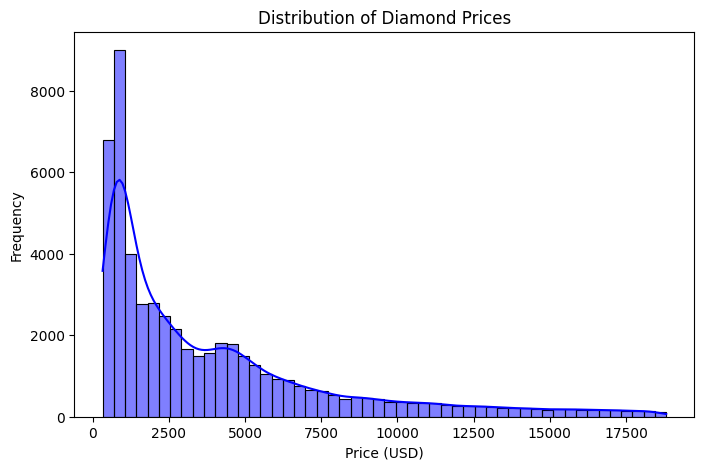

Levene's Test P-value: 3.360146858232803e-105


In [2]:
# 1. Visual Normality Check: Histogram of Price
plt.figure(figsize=(8, 5))
sns.histplot(df['price'], bins=50, kde=True, color='blue')
plt.title('Distribution of Diamond Prices')
plt.xlabel('Price (USD)')
plt.ylabel('Frequency')
plt.savefig('price_distribution.png')
plt.show()

# 2. Homoscedasticity Check: Levene's test for equal variance across cut categories
ideal = df[df['cut'] == 'Ideal']['price']
premium = df[df['cut'] == 'Premium']['price']
very_good = df[df['cut'] == 'Very Good']['price']
good = df[df['cut'] == 'Good']['price']
fair = df[df['cut'] == 'Fair']['price']

stat, p_value = stats.levene(ideal, premium, very_good, good, fair)
print("Levene's Test P-value:", p_value)

In [3]:
import scipy.stats as stats

# Ensure the variables are defined from the previous step
ideal = df[df['cut'] == 'Ideal']['price']
premium = df[df['cut'] == 'Premium']['price']
very_good = df[df['cut'] == 'Very Good']['price']
good = df[df['cut'] == 'Good']['price']
fair = df[df['cut'] == 'Fair']['price']

print("--- HYPOTHESIS TESTING RESULTS ---")

# Hypothesis 1: One-Way ANOVA across all cut categories
# (Note: With N > 50,000, ANOVA remains robust despite normality violations)
f_stat, p_anova = stats.f_oneway(ideal, premium, very_good, good, fair)
print(f"1. ANOVA P-value (All Cuts): {p_anova}")

# Hypothesis 2: Welch's T-Test (Ideal vs Premium)
# equal_var=False adjusts for the unequal variances we found in Levene's test
t_stat, p_ttest = stats.ttest_ind(ideal, premium, equal_var=False)
print(f"2. Welch's T-Test P-value (Ideal vs Premium): {p_ttest}")

# Hypothesis 3: Chi-Square Test (Independence between Cut and Color)
contingency_table = pd.crosstab(df['cut'], df['color'])
chi2_stat, p_chi2, dof, expected = stats.chi2_contingency(contingency_table)
print(f"3. Chi-Square P-value (Cut vs Color): {p_chi2}")

--- HYPOTHESIS TESTING RESULTS ---
1. ANOVA P-value (All Cuts): 8.42830730759452e-150
2. Welch's T-Test P-value (Ideal vs Premium): 1.718904661909504e-135
3. Chi-Square P-value (Cut vs Color): 1.3945120919852248e-51
